In [7]:
import sys
from pathlib import Path
if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')
DATA_DIR = Path('/content/drive/MyDrive/DeepMinds')   # shared folder: holds project_utils.py + torch_models.py
sys.path.append(str(DATA_DIR))
FIG_DIR = DATA_DIR / 'figures'; FIG_DIR.mkdir(exist_ok=True)
LOG = DATA_DIR / 'results_log.csv'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [8]:
import torch
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from project_utils import URL_FEATURES, load_master, get_feature_splits, evaluate_model, log_result
from torch_models import fit_char_cnn, fit_mlp, predict_proba, count_params

df = load_master(DATA_DIR)

def log_cnn(name, experiment, model, hist, cfg, seqs, split_col='split'):
    X_val, y_val = seqs['val']
    res = evaluate_model(name, 'val', y_val, predict_proba(model, X_val, x_dtype=torch.long),
                         save_path=FIG_DIR / f'cm_{experiment.split(": ")[1].replace(" ", "_")}_cnn.png')
    log_result(res, {'family': 'CNN', 'experiment': experiment, 'features': 'raw URL', 'split_col': split_col,
                     'params': count_params(model), 'best_epoch': hist['best_epoch'], **cfg}, LOG)
    return res


label  0           
0      https://www.    1.000
1      https://        0.463
       http://www.     0.389
       http://         0.123
       https://www.    0.024
Name: proportion, dtype: float64
                    Model Split  Accuracy  Precision  Recall    F1  ROC-AUC  PR-AUC  False positives  False negatives
Char-CNN, prefix stripped   val    0.9014     0.9647  0.7988 0.874   0.9403  0.9462              443             3046


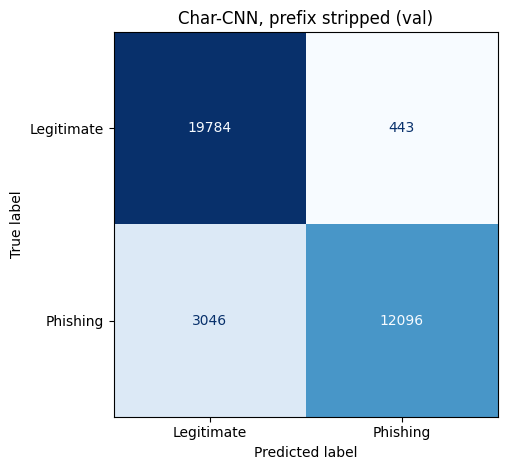

{'Model': 'Char-CNN, prefix stripped',
 'Split': 'val',
 'Accuracy': 0.9013542933076988,
 'Precision': 0.9646702288858761,
 'Recall': 0.7988376700567956,
 'F1': 0.8739568657201691,
 'ROC-AUC': np.float64(0.940250421942886),
 'PR-AUC': np.float64(0.9461690079979566),
 'False positives': 443,
 'False negatives': 3046}

In [3]:
#Ablation 1:stripping prefix
print(df['URL'].str.extract(r'^(https?://(?:www\.)?)')[0].fillna('(none)')
      .groupby(df['label']).value_counts(normalize=True).round(3))   # how prefixes differ by class
model, hist, cfg, seqs, _ = fit_char_cnn(df, {'strip_prefix': True}, verbose=False)
log_cnn('Char-CNN, prefix stripped', 'ablation: prefix stripped', model, hist, cfg, seqs)

                   Model Split  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC  False positives  False negatives
Char-CNN, no conv layers   val    0.8916     0.9449  0.7931 0.8624   0.9186  0.9328              700             3133


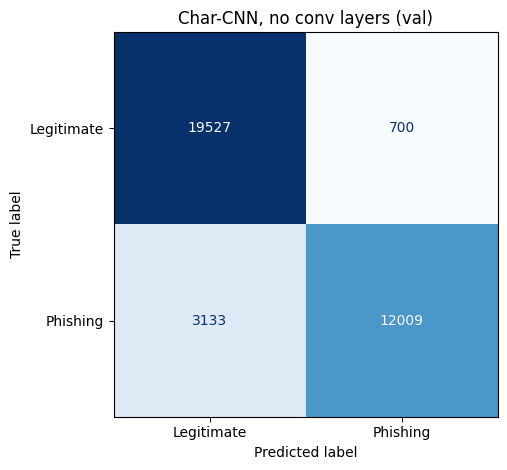

{'Model': 'Char-CNN, no conv layers',
 'Split': 'val',
 'Accuracy': 0.8916282620373773,
 'Precision': 0.9449209221811314,
 'Recall': 0.7930920618148197,
 'F1': 0.8623747800797099,
 'ROC-AUC': np.float64(0.9186099626980436),
 'PR-AUC': np.float64(0.9327655312639241),
 'False positives': 700,
 'False negatives': 3133}

In [4]:
#Ablation 2: no convolution layers
model, hist, cfg, seqs, _ = fit_char_cnn(df, {'use_conv': False}, verbose=False)
log_cnn('Char-CNN, no conv layers', 'ablation: no conv', model, hist, cfg, seqs)

           Model Split  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC  False positives  False negatives
LR, domain split   val    0.9997        1.0  0.9992 0.9996   0.9998  0.9999                0               12


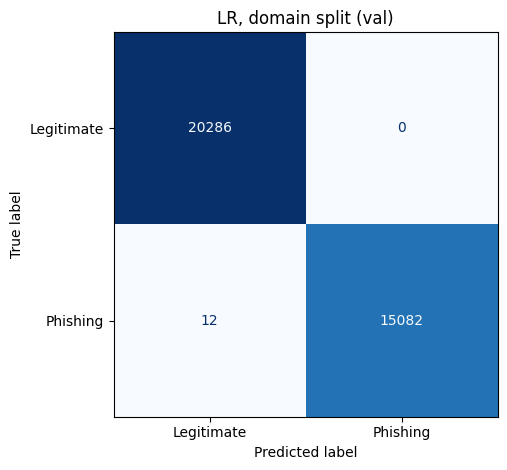

           Model Split  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC  False positives  False negatives
RF, domain split   val    0.9999        1.0  0.9997 0.9998   0.9999  0.9998                0                5


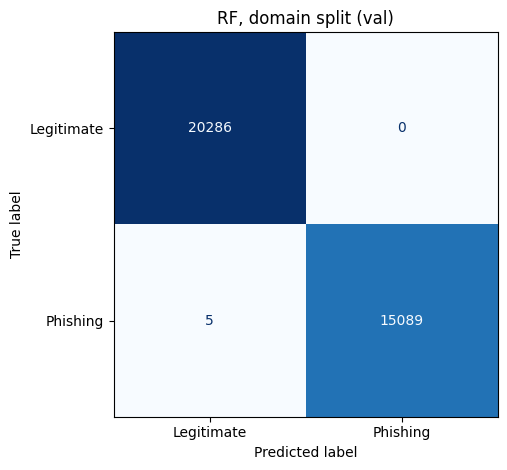

            Model Split  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC  False positives  False negatives
MLP, domain split   val    0.9999        1.0  0.9997 0.9998   0.9999  0.9999                0                5


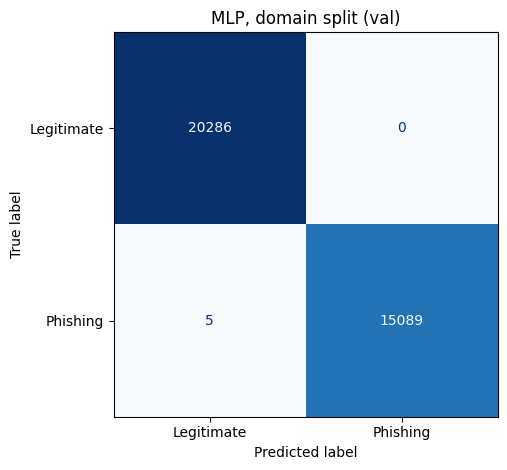

                 Model Split  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC  False positives  False negatives
Char-CNN, domain split   val     0.998     0.9999  0.9955 0.9977   0.9988   0.999                1               68


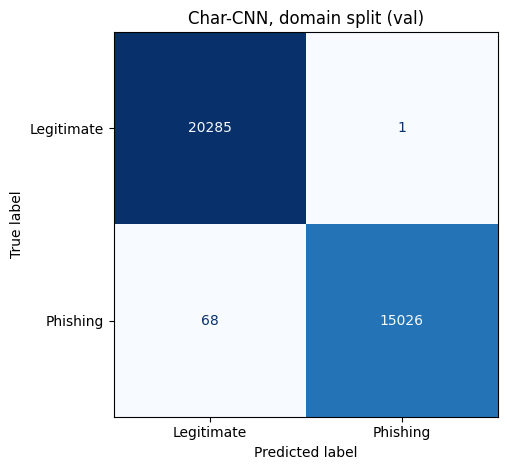

{'Model': 'Char-CNN, domain split',
 'Split': 'val',
 'Accuracy': 0.9980497456189937,
 'Precision': 0.9999334531177214,
 'Recall': 0.9954948986352193,
 'F1': 0.9977092394010822,
 'ROC-AUC': np.float64(0.9987990374193357),
 'PR-AUC': np.float64(0.9990446435481017),
 'False positives': 1,
 'False negatives': 68}

In [5]:
#Ablation 3: domain-grouped split, all four models
SPLIT = 'split_domain'
data, _ = get_feature_splits(df, URL_FEATURES, split_col=SPLIT)
(Xtr, ytr), (Xva, yva) = data['train'], data['val']
tag = {'experiment': 'ablation: domain split', 'features': 'url22', 'split_col': SPLIT}

m = LogisticRegression(C=1.0, max_iter=1000, random_state=42).fit(Xtr, ytr)
log_result(evaluate_model('LR, domain split', 'val', yva, m.predict_proba(Xva)[:, 1]), {'family': 'LR', 'C': 1.0, **tag}, LOG)

m = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1).fit(Xtr, ytr)
log_result(evaluate_model('RF, domain split', 'val', yva, m.predict_proba(Xva)[:, 1]), {'family': 'RF', 'n_estimators': 100, **tag}, LOG)

m, h, c = fit_mlp(data, verbose=False)
log_result(evaluate_model('MLP, domain split', 'val', yva, predict_proba(m, Xva)), {'family': 'MLP', **tag, **c}, LOG)

model, hist, cfg, seqs, _ = fit_char_cnn(df, {}, split_col=SPLIT, verbose=False)
log_cnn('Char-CNN, domain split', 'ablation: domain split', model, hist, cfg, seqs, split_col=SPLIT)



In [10]:
#table for the report
log = pd.read_csv(LOG)
log = log[log['Split'] == 'val']
is_abl = (log['hp_experiment'] == 'main') | log['hp_experiment'].str.startswith('ablation', na=False)
abl = log[is_abl]
# for the no-URLSimilarityIndex test, keep only the default settings so it compares fairly with 'main'
defaults = ['LR C=1.0', 'RF n=100 depth=None', 'MLP [64, 32] drop=0.0']
no_usi = abl['hp_experiment'] == 'ablation: no URLSimilarityIndex'
abl = abl[~no_usi | abl['Model'].isin(defaults)]
print(abl[['hp_family', 'hp_experiment', 'F1', 'Recall', 'False negatives', 'False positives']]
      .drop_duplicates(['hp_family', 'hp_experiment'], keep='last').round(4).to_string(index=False))

hp_family                   hp_experiment     F1  Recall  False negatives  False positives
       LR                            main 0.9996  0.9993               11                0
       RF                            main 0.9998  0.9996                6                0
      MLP                            main 0.9997  0.9994                9                0
      CNN                            main 0.9978  0.9956               66                1
       LR ablation: no URLSimilarityIndex 0.9950  0.9906              143                8
       RF ablation: no URLSimilarityIndex 0.9959  0.9945               83               41
      MLP ablation: no URLSimilarityIndex 0.9971  0.9941               89                0
      CNN       ablation: prefix stripped 0.8740  0.7988             3046              443
      CNN               ablation: no conv 0.8624  0.7931             3133              700
       LR          ablation: domain split 0.9996  0.9992               12                0